<a href="https://colab.research.google.com/github/franciscomjunior-sketch/DataScience_Mkt/blob/main/avaliacao_jornalismo_esportivo_completa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avaliação prática - Jornalismo Esportivo



## 1. Preparação e carregamento



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.options.display.float_format = '{:.2f}'.format
sns.set_theme(style='whitegrid', context='notebook')

ARQUIVO = 'dataset_jornalismo_esportivo_segunda_chamada.csv'
df = pd.read_csv(ARQUIVO)
df.head()

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.00,1200,180,310,4100,145,4300
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.00,720,140,260,2300,92,2500
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.00,980,195,410,1900,105,2300
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.00,650,120,300,2500,120,3800
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.00,2600,350,620,5300,190,5200


## 2. Diagnóstico da base

Verificamos dimensão, tipos, valores ausentes, duplicações e categorias. A cópia original é preservada em `df`; o tratamento é feito em `dados`.

In [ ]:
print(f'Registros e variáveis: {df.shape}')
display(df.dtypes.rename('tipo_de_dado').to_frame())
display(df.isna().sum().rename('valores_ausentes').to_frame())
print('Registros duplicados:', df.duplicated().sum())
for coluna in ['modalidade', 'tipo_conteudo', 'turno_publicacao']:
    print(f'{coluna}:', [repr(x) for x in df[coluna].unique()])

Registros e variáveis: (24, 15)


,tipo_de_dado
data_publicacao,str
portal,str
titulo,str
modalidade,str
tipo_conteudo,str
turno_publicacao,str
visualizacoes,int64
usuarios_unicos,int64
tempo_medio_segundos,float64
curtidas,int64


,valores_ausentes
data_publicacao,0
portal,0
titulo,0
modalidade,0
tipo_conteudo,0
turno_publicacao,0
visualizacoes,0
usuarios_unicos,0
tempo_medio_segundos,1
curtidas,0


Registros duplicados: 0
modalidade: ["'Futebol'", "'Basquete'", "'Vôlei'", "'Automobilismo'", "'Vôlei '"]
tipo_conteudo: ["'Notícia'", "'Análise'", "'Entrevista'", "'Reportagem'", "'Vídeo'"]
turno_publicacao: ["'Manhã'", "'Tarde'", "'Noite'"]


## 3. Tratamento e criação das cinco métricas

A modalidade recebe `str.strip()` para remover o espaço extra. A data é convertida para formato temporal. O valor ausente de tempo médio permanece ausente: ele não representa automaticamente zero segundos. A função de divisão segura transforma denominadores nulos em ausência para não criar valores infinitos.

In [ ]:
dados = df.copy()
dados['modalidade'] = dados['modalidade'].str.strip()
dados['data_publicacao'] = pd.to_datetime(dados['data_publicacao'], errors='coerce')

def divisao_segura(numerador, denominador):
    return numerador / denominador.replace(0, np.nan)

dados['total_interacoes'] = dados['curtidas'] + dados['comentarios'] + dados['compartilhamentos']
dados['taxa_engajamento_pct'] = divisao_segura(dados['total_interacoes'], dados['visualizacoes']) * 100
dados['taxa_recirculacao_pct'] = divisao_segura(dados['cliques_relacionados'], dados['visualizacoes']) * 100
dados['taxa_conversao_pct'] = divisao_segura(dados['novos_assinantes'], dados['cliques_relacionados']) * 100
dados['rpm'] = divisao_segura(dados['receita_publicitaria'], dados['visualizacoes']) * 1000
dados['frequencia_media'] = divisao_segura(dados['visualizacoes'], dados['usuarios_unicos'])

display(dados.head())
print('Ausências após o tratamento:')
print(dados.isna().sum()[dados.isna().sum() > 0])

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,...,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria,total_interacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.00,1200,...,310,4100,145,4300,1690,3.25,7.88,3.54,82.69,1.21
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.00,720,...,260,2300,92,2500,1120,4.00,8.21,4.00,89.29,1.24
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.00,980,...,410,1900,105,2300,1585,8.81,10.56,5.53,127.78,1.24
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.00,650,...,300,2500,120,3800,1070,4.46,10.42,4.80,158.33,1.23
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.00,2600,...,620,5300,190,5200,3570,5.25,7.79,3.58,76.47,1.24


Ausências após o tratamento:
tempo_medio_segundos    1
dtype: int64


## 4. Agrupamentos por modalidade, formato e horário

taxas são recalculadas após a soma de seus numeradores e denominadores, não usamos uma média simples das taxas individuais.

In [ ]:
def resumo_por(grupo):
    resumo = dados.groupby(grupo).agg(
        publicacoes=('titulo', 'count'), visualizacoes=('visualizacoes', 'sum'),
        usuarios_unicos=('usuarios_unicos', 'sum'), curtidas=('curtidas', 'sum'),
        comentarios=('comentarios', 'sum'), compartilhamentos=('compartilhamentos', 'sum'),
        cliques_relacionados=('cliques_relacionados', 'sum'), novos_assinantes=('novos_assinantes', 'sum'),
        receita_publicitaria=('receita_publicitaria', 'sum')
    )
    resumo['total_interacoes'] = resumo['curtidas'] + resumo['comentarios'] + resumo['compartilhamentos']
    resumo['taxa_engajamento_pct'] = resumo['total_interacoes'] / resumo['visualizacoes'] * 100
    resumo['taxa_recirculacao_pct'] = resumo['cliques_relacionados'] / resumo['visualizacoes'] * 100
    resumo['taxa_conversao_pct'] = resumo['novos_assinantes'] / resumo['cliques_relacionados'] * 100
    resumo['rpm'] = resumo['receita_publicitaria'] / resumo['visualizacoes'] * 1000
    resumo['frequencia_media'] = resumo['visualizacoes'] / resumo['usuarios_unicos']
    validos = dados.dropna(subset=['tempo_medio_segundos'])
    resumo['tempo_medio_ponderado_segundos'] = validos.groupby(grupo).apply(lambda x: np.average(x['tempo_medio_segundos'], weights=x['visualizacoes']), include_groups=False)
    return resumo.reset_index()

por_modalidade = resumo_por('modalidade')
por_tipo = resumo_por('tipo_conteudo')
por_turno = resumo_por('turno_publicacao')

display(por_modalidade.round(2))
display(por_tipo.round(2))
display(por_turno.round(2))

,modalidade,publicacoes,visualizacoes,usuarios_unicos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria,total_interacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_ponderado_segundos
0,Automobilismo,6,149000,121000,4330,800,1990,16100,793,24400,7120,4.78,10.81,4.93,163.76,1.23,211.63
1,Basquete,6,171000,139000,5460,910,1920,14400,617,17100,8290,4.85,8.42,4.28,100.00,1.23,185.29
2,Futebol,6,324000,266500,10460,1580,3200,25800,975,26500,15240,4.70,7.96,3.78,81.79,1.22,163.07
3,Vôlei,6,125500,100800,7190,1395,3030,12950,692,15400,11615,9.25,10.32,5.34,122.71,1.25,190.94


,tipo_conteudo,publicacoes,visualizacoes,usuarios_unicos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria,total_interacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_ponderado_segundos
0,Análise,5,135000,109800,3770,735,1550,12700,583,15400,6055,4.49,9.41,4.59,114.07,1.23,173.59
1,Entrevista,4,114000,92000,4550,780,1740,11100,530,14100,7070,6.20,9.74,4.77,123.68,1.24,275.88
2,Notícia,6,226000,188000,8490,1345,2670,17700,671,18600,12505,5.53,7.83,3.79,82.30,1.20,73.76
3,Reportagem,5,139500,112500,4280,805,2080,13950,683,19100,7165,5.14,10.00,4.90,136.92,1.24,236.77
4,Vídeo,4,155000,125000,6350,1020,2100,13800,610,16200,9470,6.11,8.90,4.42,104.52,1.24,238.13


,turno_publicacao,publicacoes,visualizacoes,usuarios_unicos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria,total_interacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_ponderado_segundos
0,Manhã,6,173000,142500,4980,850,1840,15600,681,19700,7670,4.43,9.02,4.37,113.87,1.21,119.04
1,Noite,9,308000,248500,11780,1970,4350,28400,1300,34800,18100,5.88,9.22,4.58,112.99,1.24,250.44
2,Tarde,9,288500,236300,10680,1865,3950,25250,1096,28900,16495,5.72,8.75,4.34,100.17,1.22,149.67


## 5. Correlações

Usamos Pearson e excluímos apenas a publicação sem tempo médio para a primeira relação. Correlação descreve associação linear; não demonstra que uma variável causou a outra.

In [ ]:
corr_tempo_comp = dados[['tempo_medio_segundos', 'compartilhamentos']].corr().iloc[0, 1]
corr_views_assin = dados[['visualizacoes', 'novos_assinantes']].corr().iloc[0, 1]
print(f'Correlação tempo médio x compartilhamentos: {corr_tempo_comp:.4f}')
print(f'Correlação visualizações x novos assinantes: {corr_views_assin:.4f}')

Correlação tempo médio x compartilhamentos: 0.0978
Correlação visualizações x novos assinantes: 0.5472


## 6. Visualizações obrigatórias

Os gráficos abaixo permitem comparar alcance, engajamento e a associação entre permanência e compartilhamento.

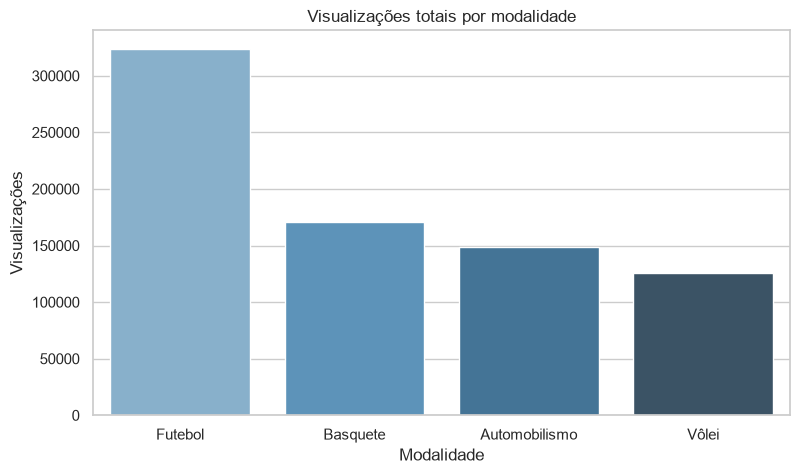

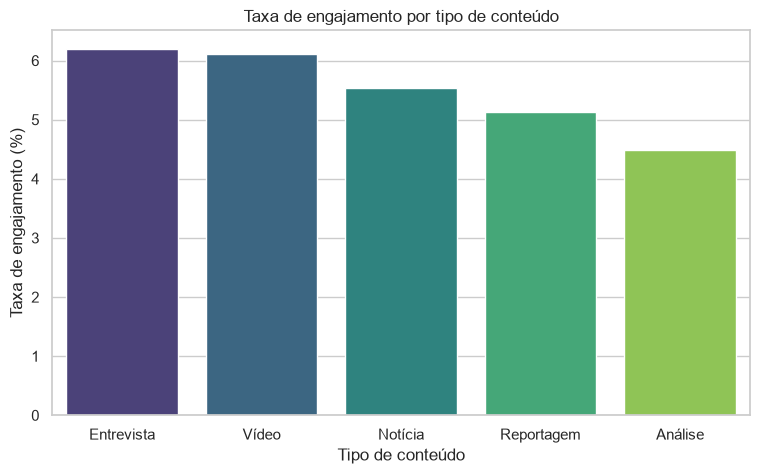

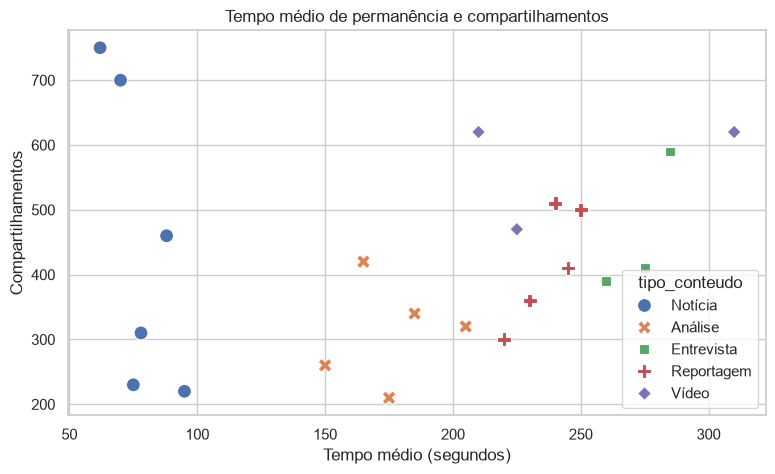

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ordem = por_modalidade.sort_values('visualizacoes', ascending=False)
sns.barplot(data=ordem, x='modalidade', y='visualizacoes', hue='modalidade', palette='Blues_d', legend=False, ax=ax)
ax.set(title='Visualizações totais por modalidade', xlabel='Modalidade', ylabel='Visualizações')
ax.ticklabel_format(style='plain', axis='y')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ordem = por_tipo.sort_values('taxa_engajamento_pct', ascending=False)
sns.barplot(data=ordem, x='tipo_conteudo', y='taxa_engajamento_pct', hue='tipo_conteudo', palette='viridis', legend=False, ax=ax)
ax.set(title='Taxa de engajamento por tipo de conteúdo', xlabel='Tipo de conteúdo', ylabel='Taxa de engajamento (%)')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=dados.dropna(subset=['tempo_medio_segundos']), x='tempo_medio_segundos', y='compartilhamentos', hue='tipo_conteudo', style='tipo_conteudo', s=100, ax=ax)
ax.set(title='Tempo médio de permanência e compartilhamentos', xlabel='Tempo médio (segundos)', ylabel='Compartilhamentos')
plt.show()

### Interpretação dos gráficos

**Visualizações por modalidade.** Futebol acumulou 324.000 visualizações, o maior alcance da amostra. Esse resultado apoia a priorização de acompanhamento quando houver valor jornalístico, mas não substitui critérios de relevância, diversidade e interesse público.

**Engajamento por formato.** Entrevista obteve 6,20% de engajamento agregado, o maior valor. É um sinal de reação proporcionalmente maior, que deve ser combinado com leitura dos temas e da qualidade dos comentários.

**Tempo e compartilhamentos.** A correlação de Pearson foi 0,0978, positiva e muito fraca. A dispersão não demonstra que aumentar o tempo de permanência causa compartilhamentos; outros fatores podem explicar os pontos.


## 7. Síntese analítica e respostas finais

- O conteúdo com mais novos assinantes foi **Os melhores lances do fim de semana**, com **190** assinantes.
- O maior RPM foi de **R$ 174,07**, no conteúdo **Tecnologia nos boxes reduz tempo de parada**.
- A correlação entre visualizações e novos assinantes foi **0,5472**. Ela indica associação positiva moderada nesta amostra, mas não causalidade.
- Recomenda-se testar formatos de entrevista em pautas relevantes e testar links contextuais em conteúdos de maior permanência, acompanhando taxas agregadas e comparando grupos semelhantes.
- Faltam dados de origem do tráfego, distribuição, perfil do público, tema e custo de produção. Portanto, esta é uma análise descritiva e não uma prova causal.

A resposta completa às oito questões, com fórmulas, interpretações, insights, recomendações, limitações e conclusão, está no relatório final em PDF. Os cálculos que sustentam as respostas estão apresentados e executados neste notebook.